In [10]:
import pandas as pd
import numpy as np
import os

In [ ]:
# Load UMI count matrix
# This is a large file — genes x cells, so transpose to cells x genes for ML
counts = pd.read_csv(
    r"C:\compbio\OA-scRNA-severity-nn\data\raw\GSE104782_allcells_UMI_count.txt.gz",
    sep="\t",
    index_col=0,
    compression="gzip"
)

# Currently shape: (genes, cells) — transpose to (cells, genes)
counts = counts.T  
print(counts.shape)  # should be (num_cells, num_genes)

# Extract severity labels from cell names e.g. "OA1_S2.15" -> 2
labels = counts.index.str.extract(r'S(\d)')[0].astype(int)
print(labels.value_counts())  # check class distribution across S0-S4

(1600, 24153)
0
0    320
1    320
2    320
3    320
4    320
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = counts.values  # numpy array (cells x genes)
y = labels.values

# Feature selection — keep only genes with variance above a threshold
# This is important, most genes will be near-zero across all cells
variances = X.var(axis=0)
top_genes = variances.argsort()[-1000:]  # keep top 1000 most variable genes
X = X[:, top_genes]

# Log normalize — standard for scRNA (UMI counts are heavily skewed)
X = np.log1p(X)  # log(x+1), handles zeros gracefully

# Scale
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [13]:
print(counts.shape)           # confirm (cells x genes)
print(counts.index[:5])       # confirm cell names look right e.g. OA1_S0.1
print(counts.columns[:5])     # confirm gene names look right e.g. A1BG
print(counts.isnull().sum().sum())  # check for missing values

(1600, 24153)
Index(['OA1_S0.1', 'OA1_S0.2', 'OA1_S0.3', 'OA1_S0.4', 'OA1_S0.5'], dtype='str')
Index(['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1'], dtype='str', name='gene')
0


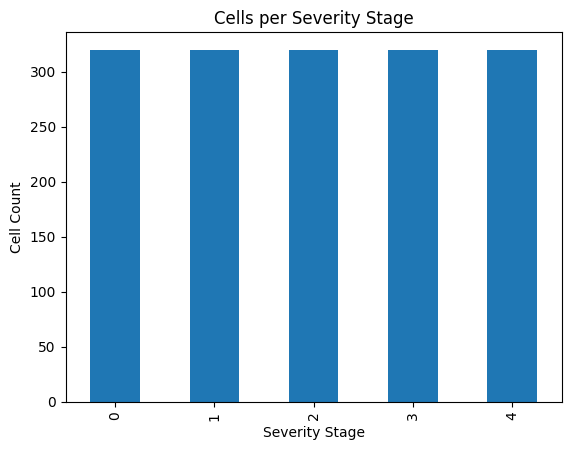

In [ ]:
import matplotlib.pyplot as plt

labels.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Severity Stage')
plt.ylabel('Cell Count')
plt.title('Cells per Severity Stage')
plt.savefig(r'C:\compbio\OA-scRNA-severity-nn\results\figures\severity_distribution.png')
plt.show()

In [15]:
sparsity = (X == 0).sum() / X.size
print(f"Sparsity: {sparsity:.1%}")  # scRNA is typically 80-95% zeros

Sparsity: 0.0%


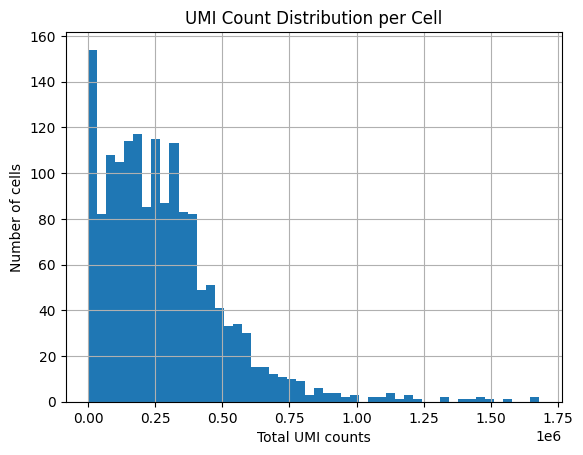

In [16]:
counts_per_cell = counts.sum(axis=1)
counts_per_cell.hist(bins=50)
plt.xlabel('Total UMI counts')
plt.ylabel('Number of cells')
plt.title('UMI Count Distribution per Cell')
plt.savefig('results/figures/umi_distribution.png')
plt.show()

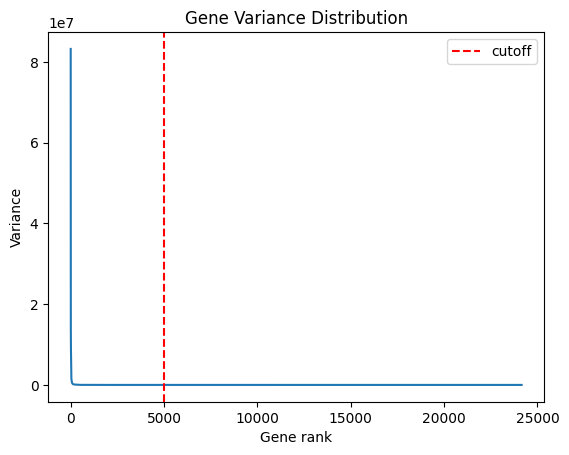

In [17]:
plt.plot(sorted(variances)[::-1])
plt.axvline(x=5000, color='red', linestyle='--', label='cutoff')
plt.xlabel('Gene rank')
plt.ylabel('Variance')
plt.title('Gene Variance Distribution')
plt.legend()
plt.savefig('results/figures/variance_distribution.png')
plt.show()

In [18]:
print(f"X shape: {X.shape}")           # should be (cells, 5000)
print(f"y shape: {y.shape}")           # should be (cells,)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train distribution: {pd.Series(y_train).value_counts().sort_index()}")
print(f"y_test distribution: {pd.Series(y_test).value_counts().sort_index()}")

X shape: (1600, 5000)
y shape: (1600,)
X_train shape: (1280, 5000)
X_test shape: (320, 5000)
y_train distribution: 0    256
1    256
2    256
3    256
4    256
Name: count, dtype: int64
y_test distribution: 0    64
1    64
2    64
3    64
4    64
Name: count, dtype: int64


In [19]:

os.makedirs('data/processed', exist_ok=True)

np.save('data/processed/X_train.npy', X_train)
np.save('data/processed/X_test.npy', X_test)
np.save('data/processed/y_train.npy', y_train)
np.save('data/processed/y_test.npy', y_test)

In [ ]:
import os
os.chdir(r'C:\compbio\OA-scRNA-severity-nn')  # force working directory to repo root

import sys
sys.path.append(r'C:\compbio\OA-scRNA-severity-nn')

from src.dataset import scRNADataset

dataset = scRNADataset('data/processed/X_train.npy', 'data/processed/y_train.npy')
print(len(dataset))
x, y = dataset[0]
print(x.shape)
print(y)

1280
torch.Size([5000])
tensor(0)


In [21]:
print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")


Train size: 1280
Test size: 320
